# Clustering

Clustering is used in this project to explore whether the Rio de Janeiro real-estate market contains groups of properties or locations with similar characteristics. 
Identifying these groups can help reveal underlying market structure that may not be evident from individual variables alone.

Besides its exploratory value, clustering may also provide useful information for the later price-prediction model. 
Cluster membership can be tested as an additional feature, allowing us to evaluate whether representing broader market segments improves the prediction of property prices per square meter.

# Import

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
filepath = "../data/processed/ITBI_featured.xlsx"

dfs_dict = pd.read_excel(filepath, sheet_name=None, index_col=0)

df = dfs_dict["transacoes"]
df_bairro = dfs_dict["bairro"]
df_logradouro = dfs_dict["logradouro"]
df_tipologia = dfs_dict["tipologia"]
df_descricao = dfs_dict["descricao"]

In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 490227 entries, 0 to 79934
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ano                490227 non-null  int64  
 1   mes                490227 non-null  int64  
 2   COD_REGIAO_FISCAL  490227 non-null  str    
 3   COD_BAIRRO         490227 non-null  int64  
 4   COD_LOGRADOURO     490227 non-null  int64  
 5   COD_TRECHO         490227 non-null  int64  
 6   COD_TIPOLOGIA      490227 non-null  int64  
 7   ID_UTILIZACAO      490227 non-null  int64  
 8   FATOR_IDADE        477475 non-null  float64
 9   vl_declarado       490227 non-null  float64
 10  area               490227 non-null  int64  
 11  valor_m2           490227 non-null  float64
 12  count_anterior     439557 non-null  float64
 13  median_anterior    439557 non-null  float64
 14  mean_anterior      439557 non-null  float64
 15  std_anterior       439557 non-null  float64
dtypes: float64(7), int6

# Preprocessing

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans

In [5]:
seasonal_features = [
    "mes"
]

categorical_features = [
    "COD_BAIRRO",
    "COD_TIPOLOGIA",
]

log_features = [
    "area",
    "valor_m2",
]

numeric_features = [
    "FATOR_IDADE",
]

In [6]:
def season_func(X):
    month = X.iloc[:, 0]

    return np.column_stack([
        np.sin(2 * np.pi * month / 12),
        np.cos(2 * np.pi * month / 12),
    ])

In [7]:
# transformer for seasonality
season_transformer = FunctionTransformer(
    season_func,
    feature_names_out = lambda transformer, input_features : ["month_sin", "month_cos"]
)

# transformer for all log-normally distributed quantitities
log_transformer = Pipeline([
    ("log", FunctionTransformer(np.log, inverse_func=np.exp, feature_names_out="one-to-one")), # convert to log space
    ("scaler", StandardScaler())
])

# transformet for the age factor
age_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", MinMaxScaler())
])

preprocessor = ColumnTransformer([
    # ("month", season_transformer, seasonal_features),
    ("log", log_transformer, log_features),
    ("num", age_transformer, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Clustering

First, let's do a general clsutering including all years.

In [8]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [10]:
%%time

results = list()
# varying the number of clusters
for k in range(3, 30):
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("kmeans", KMeans(n_clusters=k))
    ])

    X_transformed = pipeline["preprocessor"].fit_transform(df)
    labels = pipeline.fit_predict(df)
    
    results.append({
        "k": k,
        "inertia": pipeline["kmeans"].inertia_,
        "silhouette": silhouette_score(
            X_transformed, labels, sample_size=10000
        ),
        "davies_bouldin": davies_bouldin_score(
            X_transformed.toarray(), labels
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_transformed.toarray(), labels
        ),
    })

CPU times: user 5min 12s, sys: 1min 8s, total: 6min 20s
Wall time: 3min 41s


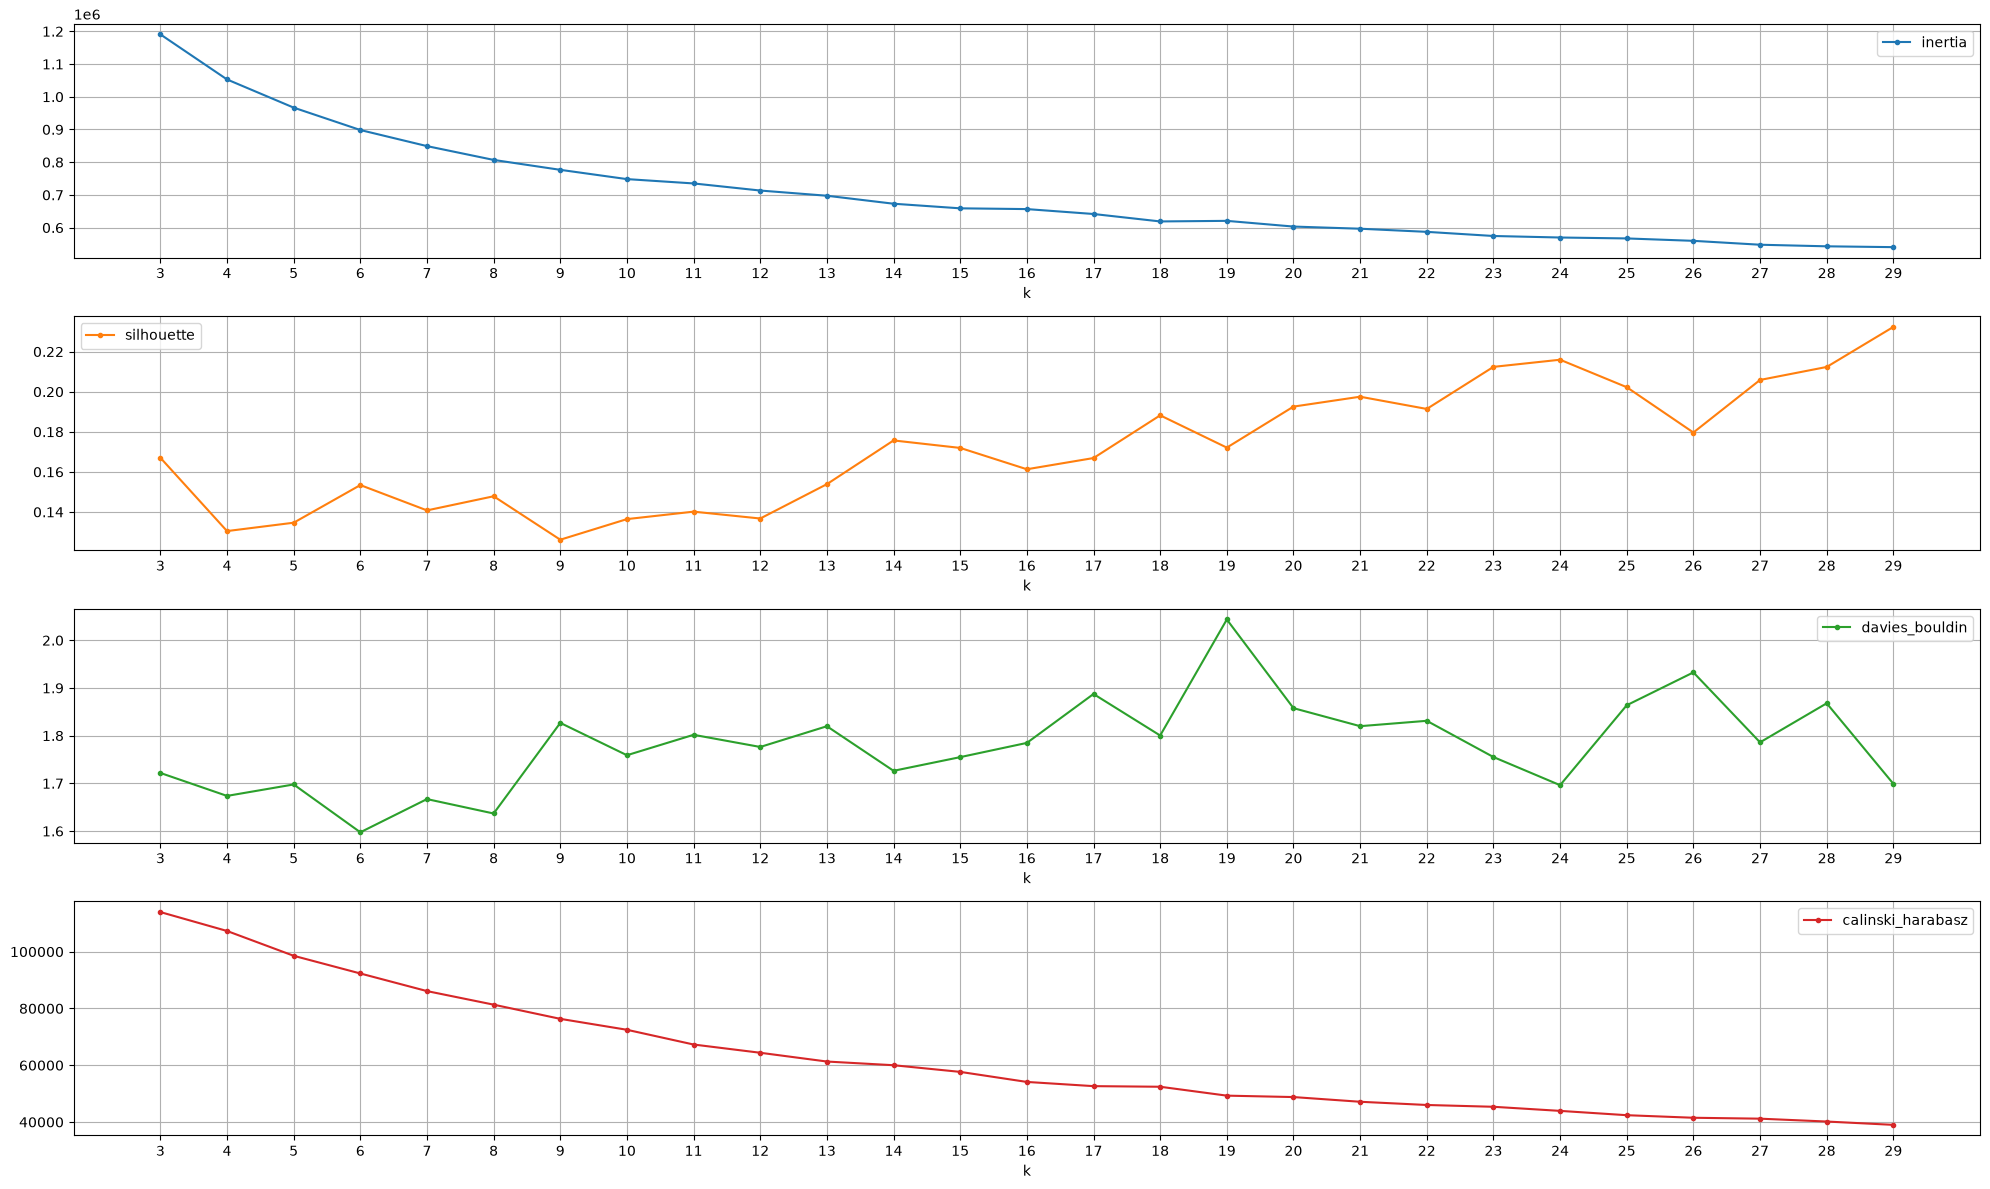

In [11]:
df_results_all = pd.DataFrame.from_dict(results).set_index("k")
df_results_all.plot(subplots=True, figsize=(20, 12), marker=".", grid=True, xticks=df_results_all.index, sharex=False)
plt.tight_layout()

Good rule of thumb for choosing the number of clusters `k`:
- Look for the "elbow" in the inertia plot.
- A higher **silhouette score** shows better cluster structure:
    - for > 0.70: strong cluster structure
    - 0.50 - 0.70: reasonably well separated
    - 0.25 - 0.50: weak to moderate structure
    - for < 0.25: little clear clustering structure
- For the **Davies–Bouldin** score, lower is better:
    - for 0.5: well-separated clusters.
    - 0.5 - 1.0: reasonably good separation.
    - 1.0 - 1.5: moderate overlap.
    - for > 1.5: weak separation.
- For **Calinski-Harabasz**, higher is better.

In [31]:
k = 6
df_results_all.loc[k]

inertia              898383.144151
silhouette                0.153418
davies_bouldin            1.597478
calinski_harabasz     92323.136134
Name: 6, dtype: float64

In [32]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("kmeans", KMeans(n_clusters=k))
])

X_transformed = pipeline["preprocessor"].transform(df)
labels = pipeline.fit_predict(df)

In [33]:
df["cluster"] = labels

<Axes: xlabel='ano', ylabel='Share (%)'>

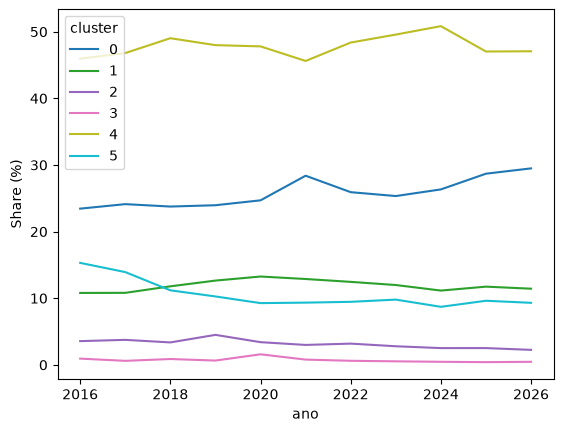

In [42]:
df_cluster_per_year = df.groupby(["cluster", "ano"]).count().valor_m2.unstack()
df_cluster_per_year /= df_cluster_per_year.sum()/100
df_cluster_per_year.T.plot(kind="line", legend=True, ylabel="Share (%)", cmap="tab10")

Over the years, the clusters are fairly steady.
The share stays more or less through the years.
There was a position flip from 2018 to between clusters 1 and 5, but in genral, steady.

Text(0, 0.5, 'Value per square meter (R$/m2)')

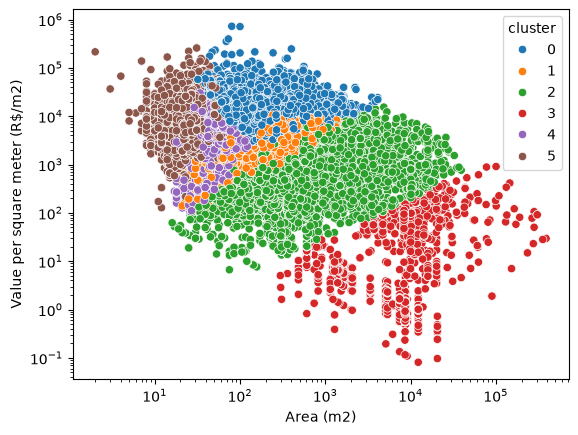

In [43]:
ax = sns.scatterplot(df, x="area", y="valor_m2", hue="cluster", legend=True, palette="tab10")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Area (m2)")
ax.set_ylabel("Value per square meter (R$/m2)")

We can roughly describe the clusters through this plot.
The statistics below will also be considered; they will be important.
Let's start with the most evident:
- Cluster 5: High-value small properties
- Cluster 0: High-value medium properties
- Cluster 2: Wide range of property sizes with low values
- Cluster 3: Large and low value properties.

Clusters 1 and 4 are in-between clusters 0, 2, and 5, but they are not negligible.
In fact, Cluster 4 is the largest cluster and the closest the the general mean of the dataset.

In [45]:
df.groupby("cluster").describe().valor_m2.sort_values("count", ascending=False)

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
4,234411.0,5557.068426,2610.324601,102.906923,3793.103448,5147.825116,6706.141383,30294.117647
0,126049.0,10801.271068,7360.502184,2302.631579,7012.987013,9345.794393,12666.666667,727203.496750
1,57856.0,3470.324691,1887.228371,138.081591,2092.313380,3083.333333,4387.755102,12500.000000
5,52926.0,8652.598623,6846.103602,128.186667,4571.428571,7047.548997,10869.565217,259021.127097
2,15539.0,929.729913,1173.738549,6.666667,242.424242,529.262087,1149.052440,15459.324129
3,3446.0,18.343995,52.202013,0.081327,1.068686,1.731277,8.001384,911.408758


In [46]:
df.valor_m2.describe()

count    490227.000000
mean       6807.793553
std        5537.337302
min           0.081327
25%        3736.522759
50%        5646.083951
75%        8510.638298
max      727203.496750
Name: valor_m2, dtype: float64

Let's try to discover the differences between clusters 1 and 4 from 0, 2, and 5.

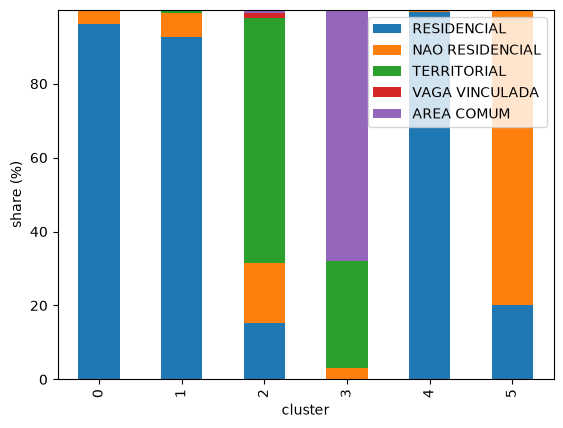

In [39]:
df_clusters_usage_share = df.groupby(["ID_UTILIZACAO", "cluster"]).count().valor_m2.unstack()
df_clusters_usage_share /= df_clusters_usage_share.sum(axis=0)/100
ax = df_clusters_usage_share.T.plot(kind="bar", stacked=True, ylabel="share (%)")
ax.legend(df_descricao.DESCRICAO) 

From the bar plot above, we can say:
- Clusters 0, 1, and 4 are basically residential.
- Cluster 5 is mostly nonresidential properties.
- Cluster 3 is dominated by land and common areas.
- Cluster 2 is mostly land.

Despite identifying that cluster 5 is mostly non-residential, no characteristics besides the price and the property's size and value are evident for clusters 0, 1, and 4.

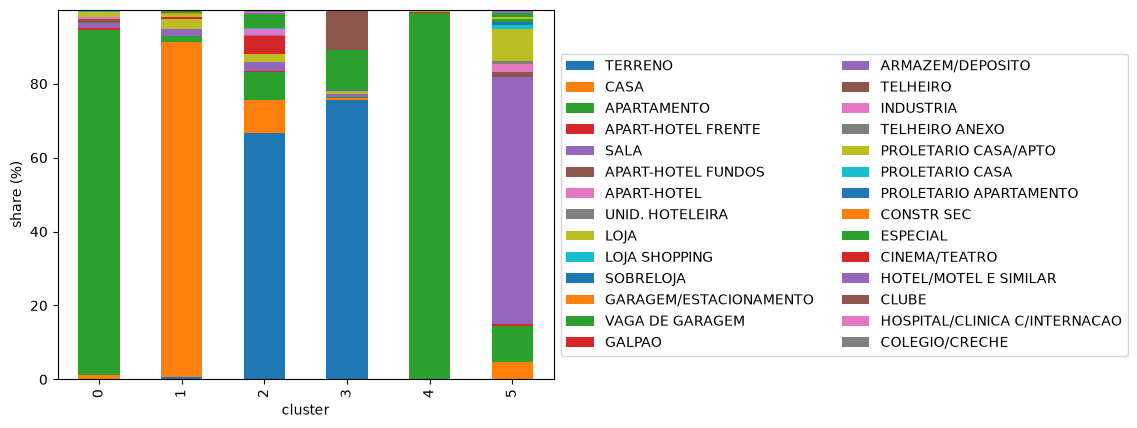

In [77]:
df_clusters_type_share = df.groupby(["COD_TIPOLOGIA", "cluster"]).count().valor_m2.unstack()
df_clusters_type_share /= df_clusters_type_share.sum(axis=0)/100
ax = df_clusters_type_share.T.plot(kind="bar", stacked=True, ylabel="share (%)")
ax.legend(df_tipologia.ds_imovel_tipologia, ncols=2, alignment="right", bbox_to_anchor=(1,.9)) 

Now we have some distinction among the clusters 0, 1, and 4.
- Clusters 0 and 4 get mostly apartments.
- Cluster 1 is mainly houses.

Because the colors can be a little bit confusing, let's list the categories of each cluster.

In [83]:
df_clusters_type_share.index = df_tipologia.ds_imovel_tipologia

for cluster in range(6):
    print(f"=== Cluster {cluster} ===")
    print(df_clusters_type_share[cluster].sort_values(ascending=False).head(5))

=== Cluster 0 ===
ds_imovel_tipologia
APARTAMENTO           93.340685
SALA                   1.457370
LOJA                   1.440710
CASA                   1.052765
APART-HOTEL FUNDOS     0.929797
Name: 0, dtype: float64
=== Cluster 1 ===
ds_imovel_tipologia
CASA           90.754632
LOJA            2.573631
SALA            1.856333
APARTAMENTO     1.595340
ESPECIAL        0.895326
Name: 1, dtype: float64
=== Cluster 2 ===
ds_imovel_tipologia
TERRENO        66.606603
CASA            8.855139
APARTAMENTO     7.831907
GALPAO          4.826565
ESPECIAL        3.983525
Name: 2, dtype: float64
=== Cluster 3 ===
ds_imovel_tipologia
TERRENO     75.507835
ESPECIAL    11.259431
CLUBE       10.737086
SALA         0.928613
CASA         0.754498
Name: 3, dtype: float64
=== Cluster 4 ===
ds_imovel_tipologia
APARTAMENTO               99.253021
LOJA                       0.357065
PROLETARIO CASA/APTO       0.176613
APART-HOTEL                0.061004
PROLETARIO APARTAMENTO     0.047353
Name: 4, dtype

In [53]:
df.groupby("cluster").FATOR_IDADE.describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,125926.0,0.708737,0.156026,0.5,0.54,0.76,0.83,1.0
1,57523.0,0.718836,0.195937,0.5,0.50,0.69,0.92,1.0
2,5726.0,0.749668,0.166850,0.5,0.57,0.80,0.85,1.0
3,985.0,0.879310,0.058677,0.5,0.84,0.88,0.88,1.0
4,234406.0,0.738196,0.167816,0.5,0.55,0.81,0.85,1.0
5,52909.0,0.849459,0.179063,0.5,0.75,0.95,1.00,1.0


It's worth noticing that Cluster 0 has the lowest mean age of all clusters.

We can summarize the analysis with the table bellow.

| Cluster | Property value | Property size | Main utilization / typology | Interpretation |
|---|---|---|---|---|
| **5** | High | Small | Mostly non-residential | Small, high-value non-residential properties |
| **0** | High | Medium | Residential, mostly apartments | High-value medium-sized apartments |
| **1** | Intermediate | Intermediate | Residential, mostly houses | Typical residential house segment |
| **4** | Intermediate | Intermediate | Residential, mostly apartments | Mainstream residential apartment segment; largest cluster and closest to the overall dataset profile |
| **2** | Low | Wide range | Mostly land | Low-value land with heterogeneous sizes |
| **3** | Low | Large | Land and common areas | Large, low-value properties, dominated by land and common areas |



In [84]:
df.groupby("cluster").valor_m2.describe()

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,126049.0,10801.271068,7360.502184,2302.631579,7012.987013,9345.794393,12666.666667,727203.496750
1,57856.0,3470.324691,1887.228371,138.081591,2092.313380,3083.333333,4387.755102,12500.000000
2,15539.0,929.729913,1173.738549,6.666667,242.424242,529.262087,1149.052440,15459.324129
3,3446.0,18.343995,52.202013,0.081327,1.068686,1.731277,8.001384,911.408758
4,234411.0,5557.068426,2610.324601,102.906923,3793.103448,5147.825116,6706.141383,30294.117647
5,52926.0,8652.598623,6846.103602,128.186667,4571.428571,7047.548997,10869.565217,259021.127097


For this first approach, let's not use clustering as a support for the supervised learning to predict the property value per square meter.
Let's keep the study of this notebook just as informational.

Clustering might be useful if we want to consider the street for the prediction.
As the dataset has 10,000+ streets, clustering might be useful for dimensionality reduction.
Let's keep this in mind for further studies.